# Getting Started with OneSimulation
Run this complete reactor model locally in the installed OneSimulation environment. Compare concentration error and the conserved total before changing k or the time step.

k = 0.800 1/s,  characteristic time 1/k = 1.25 s,  end time = 6.25 s
Maximum absolute error against the exponential: 1.998e-08 mol/m^3  (0.0000 % of C_A0)
Maximum mass-balance error C_A+C_B-C_A0: 4.441e-16 mol/m^3


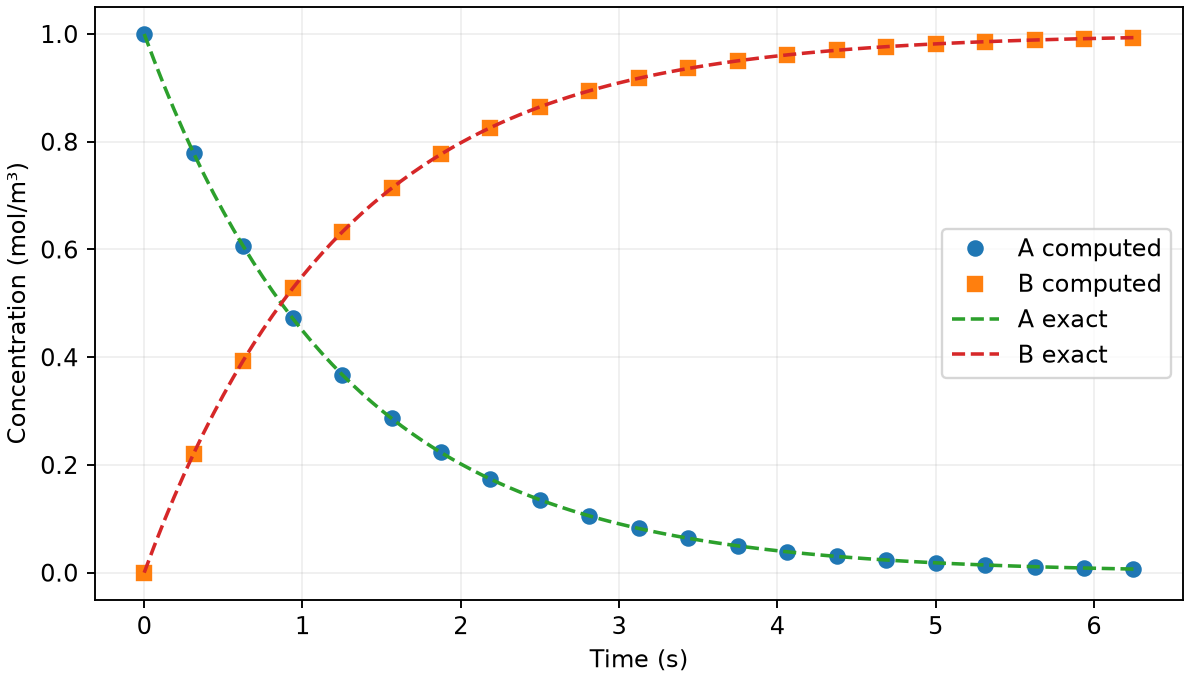

In [1]:
"""First complete OneSimulation model, verified against an exponential solution."""
import numpy as np
from onesim.cad.geometry import LumpedDomain
from onesim.meshing import LumpedMesh
from onesim.numerics import Numerics
from onesim.numerics.discretization import LumpedParameters
from onesim.numerics.time import ClassicalRungeKutta4
from onesim.physics.chemistry import (
    ReactionIR,
    ReactionKinetics,
    ReactionNetworkIR,
    SpeciesIR,
)
from onesim.simulation import Problem, Simulation
from onesim.simulation.initial_conditions import InitialValue
import matplotlib.pyplot as plt
import argparse

parser = argparse.ArgumentParser(description=__doc__)
parser.add_argument("--rate", type=float, default=0.8, help="Rate in 1/s")
parser.add_argument("--initial", type=float, default=1.0, help="Initial A in mol/m³")
parser.add_argument("--step", type=float, help="Time step in seconds (default: 0.05/rate)")
parser.add_argument("--end", type=float, help="Duration in seconds (default: 5/rate)")
args = parser.parse_args([])  # Edit the defaults above, or supply a list of CLI options here.
for value in (args.rate, args.initial, args.step, args.end):
    if value is not None and (not np.isfinite(value) or value <= 0):
        parser.error("Rate, initial concentration, step and duration must be finite and positive")
k = args.rate
C_A0 = args.initial
C_B0 = 0.0
tau = 1.0 / k
end_time = args.end if args.end is not None else 5.0 * tau
time_step = args.step if args.step is not None else 0.05 * tau
print(
    f"k = {k:.3f} 1/s,  characteristic time 1/k = {tau:.2f} s,  end time = {end_time:.2f} s"
)

network = ReactionNetworkIR(
    "first_order_decay",
    "1",
    species=(
        SpeciesIR("A", 0, 1e-27, composition={"H": 1}),
        SpeciesIR("B", 0, 1e-27, composition={"H": 1}),
    ),
    reactions=(
        ReactionIR("decay", {"A": 1}, {"B": 1}, {"kind": "constant", "value": k}),
    ),
    strict_balance=True,
)

domain = LumpedDomain()
model = ReactionKinetics(domain=domain.system, temperature=300.0, network=network)
C_A = model.concentration("A")
C_B = model.concentration("B")

problem = Problem(
    name="First-order reaction decay",
    geometry=domain,
    physics=(model,),
    initial_conditions=(
        InitialValue(C_A, C_A0),
        InitialValue(C_B, C_B0),
    ),
)
simulation = Simulation(
    problem=problem,
    mesh=LumpedMesh(domain),
    numerics=Numerics(
        spatial=LumpedParameters(),
        time_integrator=ClassicalRungeKutta4(),
    ),
)
simulation.validate().require_valid()
try:
    result = simulation.run(start_time=0.0, end_time=end_time, time_step=time_step)
except ValueError as error:
    if "negative concentrations" not in str(error):
        raise
    raise SystemExit("OneSimulation rejected a negative concentration. Reduce --step; "
                     "the browser's raw RK4 preview shows why this large step fails.") from None

times, num_A = result.field(C_A).time_series()
_, num_B = result.field(C_B).time_series()

exact_A = C_A0 * np.exp(-k * times)
exact_B = C_A0 * (1.0 - np.exp(-k * times))

err_A = float(np.max(np.abs(num_A - exact_A)))
err_B = float(np.max(np.abs(num_B - exact_B)))
rel_error = max(err_A, err_B) / C_A0
print(
    f"Maximum absolute error against the exponential: {max(err_A, err_B):.3e} mol/m^3"
    f"  ({100 * rel_error:.4f} % of C_A0)"
)

mass_error = float(np.max(np.abs(num_A + num_B - C_A0)))
print(f"Maximum mass-balance error C_A+C_B-C_A0: {mass_error:.3e} mol/m^3")

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(times, num_A, "o", markevery=5, label="A computed")
ax.plot(times, num_B, "s", markevery=5, label="B computed")
ax.plot(times, exact_A, "--", label="A exact")
ax.plot(times, exact_B, "--", label="B exact")
ax.set(xlabel="Time (s)", ylabel="Concentration (mol/m³)")
ax.grid(alpha=0.2)
ax.legend()
fig.savefig("get-started-reaction.png", dpi=170)
if k == 0.8 and C_A0 == 1.0 and end_time == 6.25 and time_step == 0.0625:
    assert max(err_A, err_B) < 3e-8
    assert mass_error < 1e-12
